# Housing Society Electricity Analysis
## Seaborn Session 8 – Relational Plots

Analysis of 24 months of electricity consumption across Wings A, B and C using Seaborn line plots, scatter plots and relational plots.

Task 1: Generate electricity data and line plot

       month wing  avg_temp_c    units_kwh
0 2024-01-01    A   22.434536  4329.480463
1 2024-01-01    B   22.585511  5137.894225
2 2024-01-01    C   21.703669  3774.123693
3 2024-02-01    A   26.079213  4656.844936
4 2024-02-01    B   24.030526  5106.938742
Total Records: 72


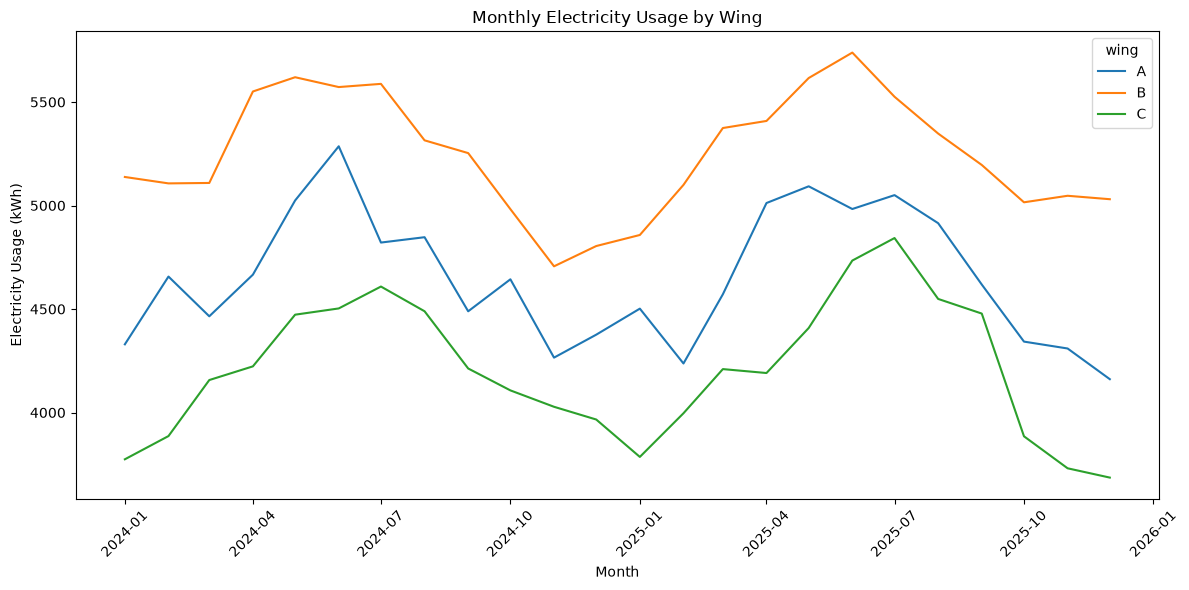

Task 1 Completed!


In [1]:

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

np.random.seed(42)

# Generate 24 months starting January 2024
months = pd.date_range(
    start="2024-01-01",
    periods=24,
    freq="MS"
)

wings = ["A", "B", "C"]

data = []

for month in months:
    for wing in wings:

        avg_temp_c = (
            28
            + 7 * np.sin(
                2 * np.pi * (month.month - 3) / 12
            )
            + np.random.normal(0, 1)
        )

        wing_base = {
            "A": 3000,
            "B": 3600,
            "C": 2500
        }[wing]

        units_kwh = (
            wing_base
            + 60 * avg_temp_c
            + np.random.normal(0, 120)
        )

        data.append([
            month,
            wing,
            avg_temp_c,
            units_kwh
        ])

df = pd.DataFrame(
    data,
    columns=[
        "month",
        "wing",
        "avg_temp_c",
        "units_kwh"
    ]
)

# Save CSV
df.to_csv("society_power.csv", index=False)

print(df.head())
print("Total Records:", len(df))

assert len(df) == 72

# Create line plot
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df,
    x="month",
    y="units_kwh",
    hue="wing"
)

plt.title("Monthly Electricity Usage by Wing")
plt.xlabel("Month")
plt.ylabel("Electricity Usage (kWh)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

print("Task 1 Completed!")


Task 2: Scatter plot of temperature vs electricity

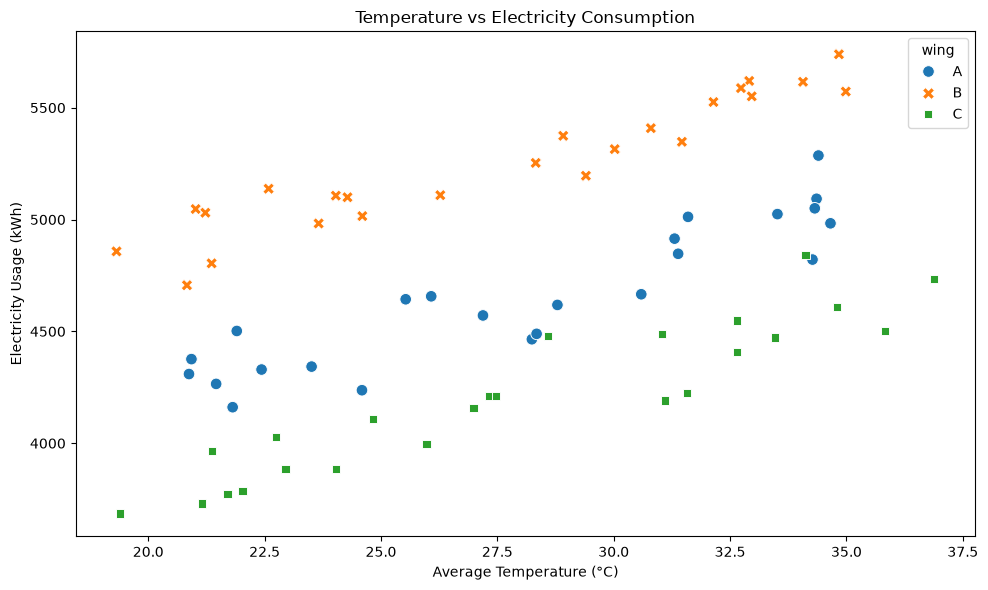

Task 2 Completed!


In [2]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="avg_temp_c",
    y="units_kwh",
    hue="wing",
    style="wing",
    s=70
)

plt.title("Temperature vs Electricity Consumption")
plt.xlabel("Average Temperature (°C)")
plt.ylabel("Electricity Usage (kWh)")

plt.tight_layout()

plt.savefig(
    "society_temp_scatter.png",
    dpi=150
)

plt.show()

print("Task 2 Completed!")


Task 3: Monthly comparison by year

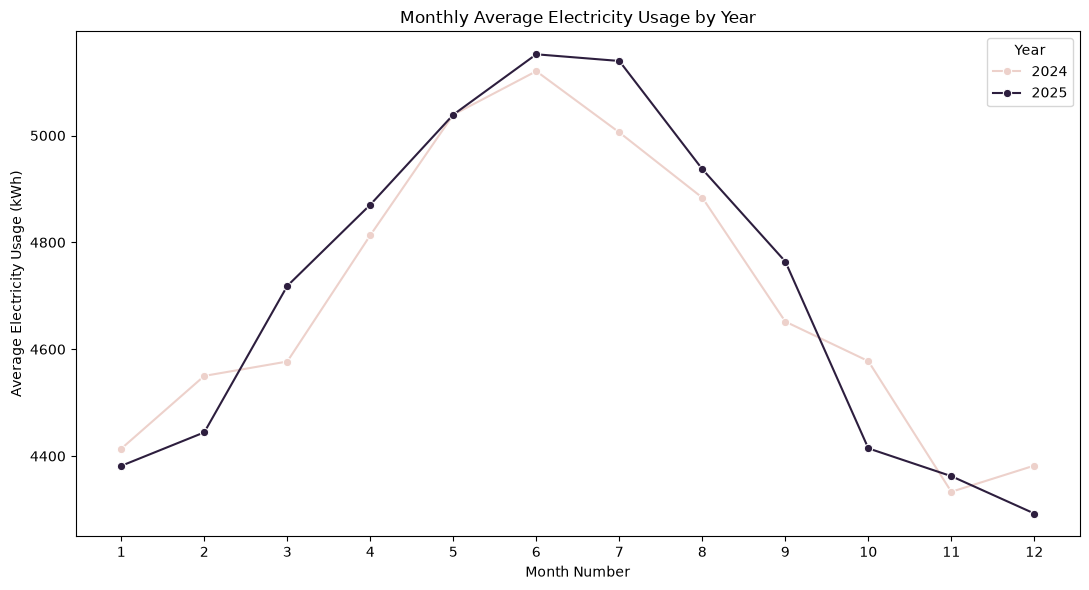

Task 3 Completed!


In [3]:

# Extract year and month number
df["year"] = df["month"].dt.year
df["month_num"] = df["month"].dt.month

# Monthly average electricity usage
plt.figure(figsize=(11, 6))

sns.lineplot(
    data=df,
    x="month_num",
    y="units_kwh",
    hue="year",
    estimator="mean",
    errorbar=None,
    marker="o"
)

plt.title("Monthly Average Electricity Usage by Year")
plt.xlabel("Month Number")
plt.ylabel("Average Electricity Usage (kWh)")

plt.xticks(range(1, 13))
plt.legend(title="Year")

plt.tight_layout()

plt.savefig(
    "society_year_compare.png",
    dpi=150
)

plt.show()

print("Task 3 Completed!")


Task 4: Final electricity report using relplot

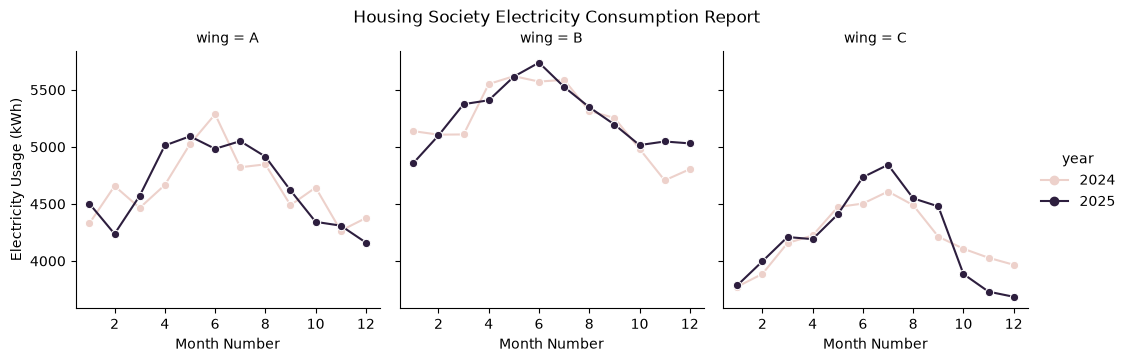

Task 4 Completed!
Session 8 Completed Successfully!


In [4]:

# Final relational plot
g = sns.relplot(
    data=df,
    x="month_num",
    y="units_kwh",
    kind="line",
    col="wing",
    hue="year",
    height=3.5,
    marker="o",
    errorbar=None
)

# Add title
g.figure.suptitle(
    "Housing Society Electricity Consumption Report",
    y=1.02
)

# Axis labels
g.set_axis_labels(
    "Month Number",
    "Electricity Usage (kWh)"
)

# Save final chart
g.savefig(
    "society_power_report.png",
    dpi=150
)

plt.show()

print("Task 4 Completed!")
print("Session 8 Completed Successfully!")
